## 1.1 Inizializzazione e configurazione di partenza

Questa cella costituisce il **setup generale** del notebook di simulazione:
importa le librerie, carica la funzione di ottimizzazione serializzata,
ridefinisce i parametri DH e calcola la cinematica diretta nella
**configurazione iniziale** `q = [0, 0, 0, 0]`.

La posizione `pi` dell'end-effector nella configurazione iniziale viene
usata come **punto di partenza** dal pianificatore cartesiano: è fondamentale
che sia calcolata tramite cinematica diretta e non assunta a priori, per
garantire coerenza tra la configurazione articolare e la posizione cartesiana
al primo istante della simulazione.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.ticker import MultipleLocator 
from matplotlib.animation import FuncAnimation
import dill

#Caricamento delle funzioni da un file utilizzando dill
with open('funzione_ottimizzazione_3giunti.pkl', 'rb') as file:
    dw_dq_3g = dill.load(file)

with open('funzione_ottimizzazione_4giunti.pkl', 'rb') as file:
    dw_dq_4g = dill.load(file)

#definizione parametri di DH 
a = np.array([0.09, 0.005, 0.035, 0.02])
d = np.array([0.0, 0.0, 0.05, 0.0])
alpha = np.array([np.pi/2, -np.pi/2 , np.pi/2, 0.0])
q = np.array([0.0, 0.0, 0.0, 0.0]) #configurazione iniziale

#definizione matrice di trasformazione di Denavit-Hartenberg
def trasf_DH(d, a, alpha, theta):
  T = np.array([
          [np.cos(theta), -np.sin(theta)*np.cos(alpha), np.sin(theta)*np.sin(alpha), a*np.cos(theta)],
          [np.sin(theta), np.cos(theta)*np.cos(alpha), -np.cos(theta)*np.sin(alpha), a*np.sin(theta)],
          [0.0,           np.sin(alpha),               np.cos(alpha),               d],
          [0.0,           0.0,                         0.0,                         1.0]
      ])
  return T

T0 = np.eye(4)
T01 = trasf_DH(d[0], a[0], alpha[0], q[0])
T12 = trasf_DH(d[1], a[1], alpha[1], q[1])
T23 = trasf_DH(d[2], a[2], alpha[2], q[2])
T34 = trasf_DH(d[3], a[3], alpha[3], q[3])                
T02 = np.matmul(T01,T12)
T03 = np.matmul(T02,T23)
T04 = np.matmul(T03,T34)

pi = T04[:3, 3] #posizione dell'EE nella configurazione iniziale
print(f"pi è {pi}")


pi è [0.15 0.   0.05]


## 1.2 Definizione delle funzioni ausiliarie

Questa cella raccoglie tutte le funzioni necessarie alla simulazione della
cinematica inversa. Sono definite in un unico blocco per chiarezza e
riutilizzabilità nei notebook successivi.

**1. `Jacobian(q)`** — calcola lo **Jacobiano geometrico** 3×4 del robot data
la configurazione articolare q. Ogni colonna rappresenta il contributo
di un giunto rotoidale alla velocità cartesiana dell'end-effector, tramite
il prodotto vettoriale zi × (o4 - oi).

**2. `inverseKinematics(q, xd, xdot, k, method, ka)`** — implementa la
**cinematica inversa differenziale** con due modalità:
- "inverse": pseudo-inversa classica, adatta a robot non ridondanti
- "inverse_redundant": pseudo-inversa con proiezione nel nullo, che
  sfrutta il grado di libertà ridondante per ottimizzare w(q).

**3. `cartesianPlanner(pi, pf, t0, tf, t)`** — genera la traiettoria cartesiana
con un **polinomio cubico** che garantisce continuità di posizione e velocità
agli estremi del segmento. L'ascissa curvilinea s(t) parametrizza il
percorso dell'EE lungo la retta pi → pf.

**4. `ottimizzazione()`** — esegue una **ricerca lineare** sul guadagno k
valutando l'errore totale di tracking (norma cumulativa) per ogni valore
nella lista fornita. Restituisce il k che minimizza l'errore, usando
la cinematica inversa classica (senza ottimizzazione nel nullo).

**5. `sing(q)`** — rileva le **singolarità cinematiche** verificando il rango
dello Jacobiano: se rank(J) < 3 il robot ha perso uno o più gradi di
libertà cartesiani e la pseudo-inversa diventa numericamente instabile.

**6. `calcolo_posa(T)`** — funzione di utilità che estrae la **posizione
cartesiana** dalla colonna di traslazione di una matrice omogenea 4×4.

In [5]:
def Jacobian(q): 
    T0 = np.eye(4)
    T01 = trasf_DH(d[0], a[0], alpha[0], q[0])
    T12 = trasf_DH(d[1], a[1], alpha[1], q[1])
    T23 = trasf_DH(d[2], a[2], alpha[2], q[2])
    T34 = trasf_DH(d[3], a[3], alpha[3], q[3])                
    T02 = np.matmul(T01,T12)
    T03 = np.matmul(T02,T23)
    T04 = np.matmul(T03,T34)

    # Estrarre gli assi z
    z0 = T0[:3, 2]
    z1 = T01[:3, 2]
    z2 = T02[:3, 2]
    z3 = T03[:3, 2]
    z4 = T04[:3, 2]

    # Estrarre le posizioni
    o0 = np.array([0, 0, 0])
    o1 = T01[:3,3]
    o2 = T02[:3,3]
    o3 = T03[:3,3]
    o4 = T04[:3,3]

    # Calcolo delle J
    J1 = np.cross(z0, o4 - o0) #prodotto vettoriale tra z0 e il vettore che va da o0 a o4
    J2 = np.cross(z1, o4 - o1)
    J3 = np.cross(z2, o4 - o2)
    J4 = np.cross(z3, o4 - o3)
    J = np.vstack((J1, J2)) #impila J1 e J2 in una riga
    J = np.vstack((J, J3)) #impila J e J3 in una riga
    J = np.vstack((J, J4)) #impila J e J4 in una riga
    J = J.T

    return J

def inverseKinematics(q, xd, xdot, k, method, ka, dw_dq = None):

    # Calcolo dello Jacobiano geometrico
    J = Jacobian(q)
    
    T0 = np.eye(4)
    T01 = trasf_DH(d[0], a[0], alpha[0], q[0])
    T12 = trasf_DH(d[1], a[1], alpha[1], q[1])
    T23 = trasf_DH(d[2], a[2], alpha[2], q[2])
    T34 = trasf_DH(d[3], a[3], alpha[3], q[3])                
    T02 = np.matmul(T01,T12)
    T03 = np.matmul(T02,T23)
    T04 = np.matmul(T03,T34)

    x = T04[:3,3] #posizione dell'organo terminale
    e = xd - x #errore tra posizione desiderata e posizione attuale
    err = np.linalg.norm(e) #norma dell'errore

    K = k * np.eye(3)  #matrice dei guadagni diagonale
    Err = np.matmul(K,e) #termine di correzione proporzionale
    J_ = np.linalg.pinv(J) #pseudo inversa destra dello Jacobiano

    if method == "inverse": 
        Qdot = np.matmul(J_, xdot + Err)

    elif method == "inverse_redundant": 
        P = np.eye(J.shape[1]) - np.matmul(J_, J) #proiettore nel nullo dello Jacobiano
        grad = np.array(dw_dq(*q), dtype=float).flatten()  # calcolo del gradiente della funzione di ottimizzazione per ogni qi
        Qdot = np.matmul(J_, xdot + Err) + ka * np.matmul(P, grad)

    return Qdot, err #vettore delle velocità angolari e errore

def cartesianPlanner(pi, pf, t0, tf, t): 
    if t <= t0: #prima dell'istante iniziale, la posizione è quella iniziale e la velcotà è nulla
        pd = pi 
        pdot = np.array([0,0,0]) 
    
    elif t <= tf: 
        A = np.array([[t0**3, t0**2, t0, 1], [tf**3, tf**2, tf, 1], [3*t0**2, 2*t0, 1, 0], [3*tf**2, 2*tf, 1, 0]]) #matrice dei coefficienti del polinomio cubico

        b = np.array([[0],[np.linalg.norm(pf-pi)],[0],[0]]) #sono i vincoli 

        x = np.linalg.solve(A, b) #sono le incognite 

        s = x[0]*t**3+x[1]*t**2+x[2]*t+x[3] #calcolo ascissa curvilinea
        sdot = 3*x[0]*t**2+2*x[1]*t+x[2] #derivata dell'ascissa curvilinea
    
        pd = pi + s*(pf-pi)/np.linalg.norm(pf-pi) #posizione desiderata dell'EE
        pdot = sdot*(pf-pi)/np.linalg.norm(pf-pi) #velocità desiderata dell'EE

    elif t > tf: #dopo l'istante finale, la posizione è quella finale e la velocità è nulla
        pd = pf
        pdot = np.array([0,0,0])

    return pd, pdot

#OTTIMIZZAZIONE DEI GUADAGNI

def ottimizzazione(k_list, pA, pB, pC, t0, tm, tf, time, dt ):
    combinations = []
    for k in k_list:
        Qd = np.zeros((len(time), 4))
        error = np.zeros(len(time))
        for i in range(len(time)): #per ogni istante di tempo, calcolo la posizione desiderata e la velocità desiderata dell'EE, poi calcolo le velocità angolari e l'errore
            if time[i] <= tm:
                pd, pdot = cartesianPlanner(pA, pB, t0, tm, time[i])
            else:
                pd, pdot = cartesianPlanner(pB, pC, tm, tf, time[i])
            
            qddot, e = inverseKinematics(Qd[i], pd, pdot, k, "inverse", 0) 
            error[i] = e

            if i + 1 < len(time):
                Qd[i + 1] = Qd[i] + dt * qddot
        
        errore_rms = np.sqrt(np.mean(np.square(error)))
        combinations.append([k, errore_rms])
    
    combinations_array = np.array(combinations)
    min_error_i = np.argmin(combinations_array[:, 1])
    k_best = combinations_array[min_error_i, 0]

    return k_best


def sing(q):
    J = Jacobian(q)
    rank_J = np.linalg.matrix_rank(J)
    if(rank_J < 3):
        print("singolarità")

#Definizione funzione per calcolo posa end-effector
def calcolo_posa(T):
    p = T[0:3,3]
    return p


## 1.3 Simulazione della cinematica inversa: confronto con e senza funzionale

Questa cella contiene il **main** della simulazione. I due casi vengono
eseguiti in sequenza e i risultati confrontati graficamente:

- **Caso 1 — senza funzionale** (`method="inverse"`): cinematica inversa
  classica con pseudo-inversa. Il guadagno `k` viene scelto automaticamente
  tramite la funzione `ottimizzazione()`, che minimizza l'errore cumulativo
  di tracking su una lista di valori candidati.

- **Caso 2 — con funzionale** (`method="inverse_redundant"`): cinematica
  inversa ridondante con proiezione nel nullo. I guadagni `k=180` e `ka=15`
  sono stati determinati nel file `guadagni_funzionale`. Il
  termine `ka·P·∇w` spinge i giunti verso il centro del loro range senza
  alterare la traiettoria cartesiana dell'end-effector.

- **Caso 3 — con funzionale su 3 giunti** (`method="inverse_redundant"`): cinematica
  inversa ridondante con proiezione nel nullo. I guadagni `k=180` e `ka=10`
  sono stati determinati nel file `guadagni_funzionale`. Il
  termine `ka·P·∇w` spinge i primi tre giunti verso il centro del loro range senza
  alterare la traiettoria cartesiana dell'end-effector.

In entrambi i casi il loop principale segue lo stesso schema ad ogni
istante `i`:
1. pianificazione cartesiana → `pd`, `pdot`
2. cinematica inversa → `qdot`, `errore`
3. verifica singolarità
4. cinematica diretta → aggiornamento posizioni dei giunti
5. integrazione di Eulero → `q(i+1) = q(i) + qdot·dt`

I risultati vengono salvati su file `.txt` e visualizzati in due figure:
la prima mostra la traiettoria pianificata nello spazio cartesiano, la
seconda confronta posizione reale vs desiderata e l'errore di tracking
nei due casi.


k migliore è 180.0


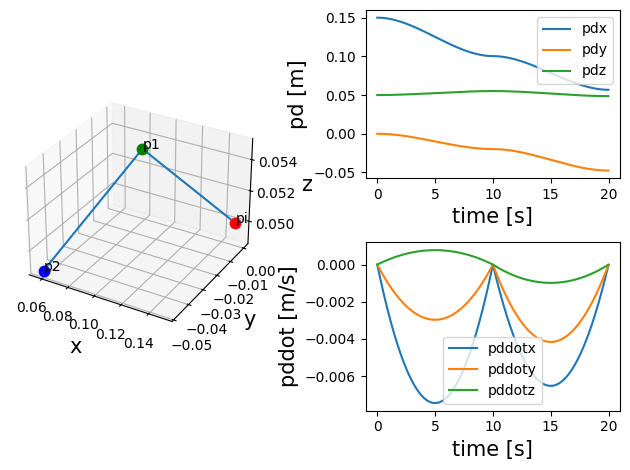

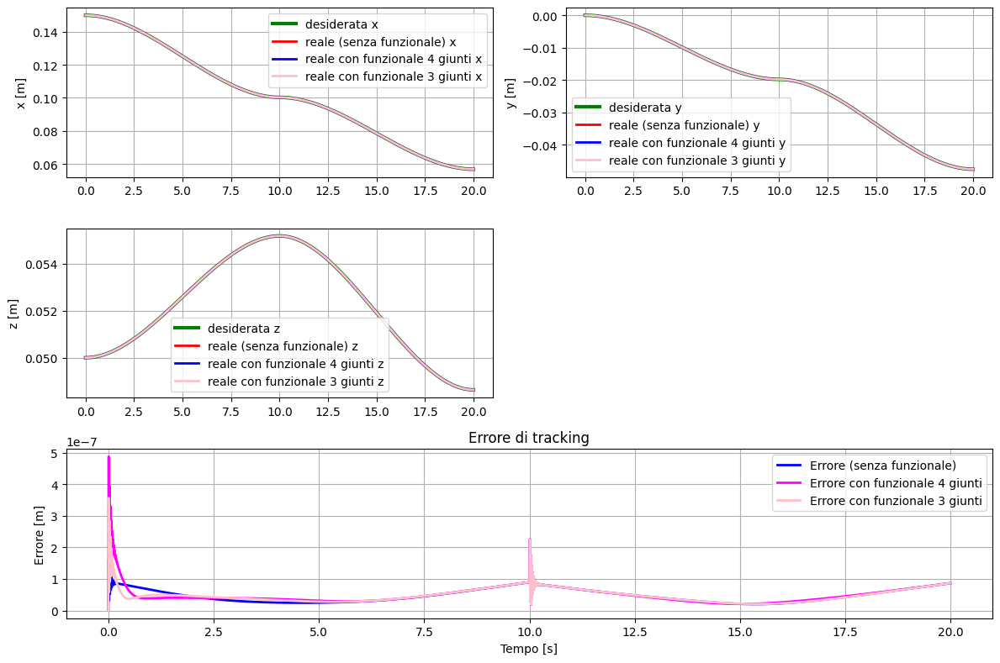

In [ ]:
if __name__ == '__main__':
    P0 = T04[:3,3] #posizione iniziale dell'EE
    P1 = np.array([0.100316, -0.019790, 0.055185])
    P2 = np.array([0.056810, -0.047541, 0.048630])


    t0 = 0  #tempo iniziale
    tm = 10  #tempo di transizione tra i due segmenti di traiettoria  
    tf = 20  #tempo finale
    dt = 0.01  #passo di tempo

    time = np.arange(t0, tf, dt) # vettore di istanti di tempo per la simulazione, da t0 a tf con passo dt

    #1. CASO SENZA FUNZIONALE 

    # Inizializzazione SPAZIO DEI GIUNTI
    q = np.array([0, 0, 0, 0]) #posizione iniziale dei giunti

    T0 = np.eye(4)
    T01 = trasf_DH(d[0], a[0], alpha[0], q[0])
    T12 = trasf_DH(d[1], a[1], alpha[1], q[1])
    T23 = trasf_DH(d[2], a[2], alpha[2], q[2])
    T34 = trasf_DH(d[3], a[3], alpha[3], q[3])                
    T02 = np.matmul(T01,T12)
    T03 = np.matmul(T02,T23)
    T04 = np.matmul(T03,T34) 

    Qd = np.zeros((len(time),4)) #vettore delle configurazioni dei giunti nel tempo
    Qdot = np.zeros((len(time),4)) #vettore delle velocità dei giunti nel tempo
    Qd[0,:] = q #posizione iniziale dei giunti
    Qdot[0,:]=np.array([0,0,0,0]) #velocità iniziale dei giunti

    # Inizializzazione SPAZIO OPERATIVO
    Pd = np.zeros((len(time),3)) #vettore delle posizioni desiderate dell'EE nel tempo derivanti dalla pianificazione di traiettoria
    Pddot = np.zeros((len(time),3)) #vettore delle velocità desiderate dell'EE nel tempo derivanti dalla pianificazione di traiettoria
    Pd[0,:] = P0 #posizione iniziale dell'EE

    # Vettori delle posizioni dei giunti nel tempo (necessario per visualizzazione)
    p_1 = np.zeros((len(time),3)) 
    p_1[0,:] = calcolo_posa(T01)  
    p_2 = np.zeros((len(time),3)) 
    p_2[0,:] = calcolo_posa(T02)  
    p_L = np.zeros((len(time),3))  
    z_locale_T02 = T02[:3, 2] # vettore z locale alla matrice di trasformazione T02
    p_L[0,:] = p_2[0,:] + d[2] * z_locale_T02 # il punto L è solidale al secondo giunto 
    p_3 = np.zeros((len(time),3)) 
    p_3[0,:] = calcolo_posa(T03) 
    p_ee = np.zeros((len(time),3)) # vettore delle posizioni effettive dell'EE nel tempo
    p_ee[0,:] = calcolo_posa(T04) # posizione iniziale dell'EE

    errore = np.zeros((len(time), 1)) # vettore dell'errore, calcolo il valore per ogni istante
    errore[0] = 0 

    # MAIN LOOP
    ka = 0 
    k_list  = list(range(20, 300, 20)) # lista dei guadagni da testare per l'ottimizzazione
    k = ottimizzazione(k_list, P0, P1, P2, t0, tm, tf, time, dt) #ottimizzazione dei guadagni, restituisce il valore di k che minimizza l'errore totale
    print(f"k migliore è {k}")

    for i in range(0, len(time)):
        if time[i] <= tm: #calcolo posizione desiderata e velocità desiderata dell'EE in base alla pianificazione di traiettoria
            pd, pdot = cartesianPlanner(P0, P1, t0, tm, time[i])

        else:
            pd, pdot = cartesianPlanner(P1, P2, tm, tf, time[i]) 

        # Inversione cinematica
        qdot, errore[i] = inverseKinematics(Qd[i,:], pd, pdot, k, "inverse", ka) # utilizzo le posizioni desierate dell'EE per calcolare le velocità angolari dei giunti e l'errore

        sing(Qd[i,:]) #verifica singolarità

        # Aggiornamento dei vettori
        Qdot[i,:] = qdot 
        Pd[i,:] = pd
        Pddot[i,:] = pdot

        T01 = trasf_DH(d[0], a[0], alpha[0], Qd[i,0])
        T12 = trasf_DH(d[1], a[1], alpha[1], Qd[i,1])
        T23 = trasf_DH(d[2], a[2], alpha[2], Qd[i,2])
        T34 = trasf_DH(d[3], a[3], alpha[3],Qd[i,3])
        T02 = np.matmul(T01,T12)
        T03 = np.matmul(T02,T23) 
        T04 = np.matmul(T03,T34)
        z_locale_T02 = T02[:3, 2]
        p_1[i,:] = T01[:3,3]
        p_2[i,:] = T02[:3,3]
        p_L[i,:] = p_2[i,:] + d[2] * z_locale_T02
        p_3[i,:] = T03[:3,3] 
        p_ee[i,:] = T04[:3,3]

        # Integrazione numerica, trovo la configurazione successiva
        if i+1< len(time):
            Qd[i+1,:]=Qd[i,:]+dt*qdot
            
    np.savetxt('posizioni_giunti.txt', Qd, fmt='%.6f')
    np.savetxt('posizion_EE.txt', p_ee, fmt='%.6f')      

    #2. CASO CON FUNZIONALE (4 GIUNTI)

    # Inizializzazione SPAZIO DEI GIUNTI
    q0_func = np.array([0,0,0,0]) # posizione iniziale dei giunti
    Qd_func = np.zeros((len(time), 4)) # vettore delle configurazioni desiderate dei giunti nel tempo
    Qd_func[0,:] = q0_func # posizione iniziale dei giunti

    T01 = trasf_DH(d[0], a[0], alpha[0], q0_func[0])
    T12 = trasf_DH(d[1], a[1], alpha[1], q0_func[1])
    T23 = trasf_DH(d[2], a[2], alpha[2], q0_func[2])
    T34 = trasf_DH(d[3], a[3], alpha[3], q0_func[3])
    T02 = T01 @ T12
    T03 = T02 @ T23
    T04 = T03 @ T34

    Qdot_func = np.zeros((len(time), 4)) # vettore delle velocità angolari desiderate dei giunti nel tempo 
    Qdot_func[0,:] = np.array([0,0,0,0]) # velocità iniziale dei giunti

    # Inizializzazione SPAZIO OPERATIVO
    p_1_func = np.zeros((len(time),3))   # 
    p_2_func = np.zeros((len(time),3))   # inizializzo i vettori delle posizioni dei giunti e dell'EE nel tempo
    p_L_func = np.zeros((len(time),3))   # 
    p_3_func = np.zeros((len(time),3))   #
    p_ee_func = np.zeros((len(time),3))  # 

    p_1_func[0,:] = calcolo_posa(T01)  # 
    p_2_func[0,:] = calcolo_posa(T02)  #  segno le posizioni iniziali dei giunti e dell'EE
    z_locale_T02 = T02[:3, 2]
    p_L_func[0,:] = p_2_func[0,:] + d[2] * z_locale_T02  
    p_3_func[0,:] = calcolo_posa(T03)  # 
    p_ee_func[0,:] = calcolo_posa(T04) # 
    
    pd_func = np.zeros((len(time),3))  # posizione desidertra dell'EE nel tempo derivante dalla pianificazione di traiettoria
    pd_func[0,:]= P0  #posizione iniziale dell'EE
    pdot_func = np.zeros((len(time),3)) #velocità desiderata dell'EE nel tempo derivante dalla pianificazione di traiettoria

    error_func=np.zeros((len(time),1))
    error_func[0]=0 

    # MAIN LOOP
    # guadagni derivanti da guadagni_funzionale
    ka = 15
    k = 180 

    for i in range(0, len(time)):
        if time[i] <= tm:
            pd_f, pdot_f = cartesianPlanner(P0, P1, t0, tm, time[i])
        else:
            pd_f, pdot_f = cartesianPlanner(P1, P2, tm, tf, time[i])

        qdot_func, error_func[i] = inverseKinematics(Qd_func[i,:], pd_f, pdot_f, k, "inverse_redundant", ka, dw_dq_4g)
        
        sing(Qd_func[i,:]) #verifica singolarità

        # aggiornamento dei vettori
        Qdot_func[i,:] = qdot_func   
        pd_func[i,:] = pd_f 
        pdot_func[i,:] = pdot_f

        T01 = trasf_DH(d[0], a[0], alpha[0], Qd_func[i,0])
        T12 = trasf_DH(d[1], a[1], alpha[1], Qd_func[i,1])
        T23 = trasf_DH(d[2], a[2], alpha[2], Qd_func[i,2])
        T34 = trasf_DH(d[3], a[3], alpha[3], Qd_func[i,3])
        T02 = np.matmul(T01, T12)
        T03 = np.matmul(T02, T23)
        T04 = np.matmul(T03, T34)
        z_locale_T02 = T02[:3, 2]
        p_1_func[i,:] = T01[:3,3]        
        p_2_func[i,:] = T02[:3,3]
        p_L_func[i,:] = p_2_func[i,:] + d[2] * T02[:3, 2]
        p_3_func[i,:] = T03[:3,3]
        p_ee_func[i,:] = T04[:3,3]

        # Integrazione numerica, trovo la configurazione successiva
        if i+1 < len(time):
            Qd_func[i+1,:] = Qd_func[i,:] + dt * qdot_func
            
    np.savetxt('posizioni_giunti_func.txt', Qd_func, fmt='%.6f')
    np.savetxt('posizion_EE_func.txt', p_ee_func, fmt='%.6f')  

    # 3. CASO CON FUNZIONALE (3 GIUNTI)

    k = 180
    ka = 10
    
    # Inizializzazione SPAZIO DEI GIUNTI
    q0_func3 = np.array([0,0,0,0]) # posizione iniziale dei giunti
    Qd_func3 = np.zeros((len(time), 4)) # vettore delle configurazioni desiderate dei giunti nel tempo
    Qd_func3[0,:] = q0_func3 # posizione iniziale dei giunti

    T01 = trasf_DH(d[0], a[0], alpha[0], q0_func3[0])
    T12 = trasf_DH(d[1], a[1], alpha[1], q0_func3[1])
    T23 = trasf_DH(d[2], a[2], alpha[2], q0_func3[2])
    T34 = trasf_DH(d[3], a[3], alpha[3], q0_func3[3])
    T02 = T01 @ T12
    T03 = T02 @ T23
    T04 = T03 @ T34

    Qdot_func3 = np.zeros((len(time), 4)) # vettore delle velocità angolari desiderate dei giunti nel tempo 
    Qdot_func3[0,:] = np.array([0,0,0,0]) # velocità iniziale dei giunti

    # Inizializzazione SPAZIO OPERATIVO
    p_1_func3 = np.zeros((len(time),3))   # 
    p_2_func3 = np.zeros((len(time),3))   # inizializzo i vettori delle posizioni dei giunti e dell'EE nel tempo
    p_L_func3 = np.zeros((len(time),3))   # 
    p_3_func3 = np.zeros((len(time),3))   #
    p_ee_func3 = np.zeros((len(time),3))  # 

    p_1_func3[0,:] = calcolo_posa(T01)  # 
    p_2_func3[0,:] = calcolo_posa(T02)  #  segno le posizioni iniziali dei giunti e dell'EE
    z_locale_T02 = T02[:3, 2]
    p_L_func3[0,:] = p_2_func3[0,:] + d[2] * z_locale_T02  
    p_3_func3[0,:] = calcolo_posa(T03)  #  
    p_ee_func3[0,:] = calcolo_posa(T04) # 
    
    pd_func3 = np.zeros((len(time),3))  # posizione desidertra dell'EE nel tempo derivante dalla pianificazione di traiettoria
    pd_func3[0,:]= P0  #posizione iniziale dell'EE
    pdot_func3 = np.zeros((len(time),3)) #velocità desiderata dell'EE nel tempo derivante dalla pianificazione di traiettoria

    error_func3=np.zeros((len(time),1))
    error_func3[0]=0 

    # MAIN LOOP
    for i in range(0, len(time)):
        if time[i] <= tm:
            pd_f, pdot_f = cartesianPlanner(P0, P1, t0, tm, time[i])
        else:
            pd_f, pdot_f = cartesianPlanner(P1, P2, tm, tf, time[i])

        qdot_func, error_func3[i] = inverseKinematics(Qd_func3[i,:], pd_f, pdot_f, k, "inverse_redundant", ka, dw_dq_3g)
        
        sing(Qd_func3[i,:]) #verifica singolarità

        # aggiornamento dei vettori
        Qdot_func3[i,:] = qdot_func   
        pd_func3[i,:] = pd_f 
        pdot_func3[i,:] = pdot_f

        T01 = trasf_DH(d[0], a[0], alpha[0], Qd_func3[i,0])
        T12 = trasf_DH(d[1], a[1], alpha[1], Qd_func3[i,1])
        T23 = trasf_DH(d[2], a[2], alpha[2], Qd_func3[i,2])
        T34 = trasf_DH(d[3], a[3], alpha[3], Qd_func3[i,3])
        T02 = np.matmul(T01, T12)
        T03 = np.matmul(T02, T23)
        T04 = np.matmul(T03, T34)
        z_locale_T02 = T02[:3, 2]
        p_1_func3[i,:] = T01[:3,3]        
        p_2_func3[i,:] = T02[:3,3]
        p_L_func3[i,:] = p_2_func3[i,:] + d[2] * T02[:3, 2]
        p_3_func3[i,:] = T03[:3,3] 
        p_ee_func3[i,:] = T04[:3,3]

        # Integrazione numerica, trovo la configurazione successiva
        if i+1 < len(time):
            Qd_func3[i+1,:] = Qd_func3[i,:] + dt * qdot_func
            
    np.savetxt('posizioni_giunti_func3.txt', Qd_func3, fmt='%.6f')
    np.savetxt('posizion_EE_func3.txt', p_ee_func3, fmt='%.6f')


    # Plot della traiettoria
    ax0 = plt.subplot(2, 2, (1, 3), projection="3d")
    ax0.plot(Pd[:, 0], Pd[:, 1], Pd[:, 2])
    ax0.plot(P0[0], P0[1], P0[2], ".", ms=15, c="r")
    ax0.plot(P1[0], P1[1], P1[2], ".", ms=15, c="g")
    ax0.plot(P2[0], P2[1], P2[2], ".", ms=15, c="b")
    ax0.text(P0[0], P0[1], P0[2], "pi")
    ax0.text(P1[0], P1[1], P1[2], "p1")
    ax0.text(P2[0], P2[1], P2[2], "p2")
    ax0.set_xlabel("x", fontsize=15)
    ax0.set_ylabel("y", fontsize=15)
    ax0.set_zlabel("z", fontsize=15)

    # Plot della posizione dell'end effector nel tempo
    ax1 = plt.subplot(2, 2, 2)
    ax1.plot(time, Pd[:, 0], label="pdx")
    ax1.plot(time, Pd[:, 1], label="pdy")
    ax1.plot(time, Pd[:, 2], label="pdz")
    ax1.set_xlabel("time [s]", fontsize=15)
    ax1.set_ylabel("pd [m]", fontsize=15)
    ax1.legend()

    # Plot della velocità dell'end effector nel tempo
    ax2 = plt.subplot(2, 2, 4)
    ax2.plot(time, Pddot[:, 0], label="pddotx")
    ax2.plot(time, Pddot[:, 1], label="pddoty")
    ax2.plot(time, Pddot[:, 2], label="pddotz")
    ax2.set_xlabel("time [s]", fontsize=15)
    ax2.set_ylabel("pddot [m/s]", fontsize=15)
    ax2.legend()

    plt.tight_layout()
    plt.show()

    # Posizione desiderata/reale
    fig = plt.figure(figsize=(12, 8))

    labels = ['x', 'y', 'z']
    for i in range(3):
        ax = plt.subplot(3, 2, i + 1)
        ax.plot(time, Pd[:, i], label=f'desiderata {labels[i]}', linewidth=3, c="green")
        ax.plot(time, p_ee[:, i], label=f'reale (senza funzionale) {labels[i]}', linewidth=2, c="red")
        ax.plot(time, p_ee_func[:, i], label=f'reale con funzionale 4 giunti {labels[i]}', linewidth=2, c="blue")
        ax.plot(time, p_ee_func3[:, i], label=f'reale con funzionale 3 giunti {labels[i]}', linewidth=2, c="pink")
        ax.set_ylabel(f'{labels[i]} [m]')
        ax.legend()
        ax.grid()

    # Errore
    ax_err = plt.subplot(3, 2, (5, 6))
    ax_err.plot(time, errore, 'blue', linewidth=2, label='Errore (senza funzionale)')
    ax_err.plot(time, error_func, 'magenta', linewidth=2, label='Errore con funzionale 4 giunti')
    ax_err.plot(time, error_func3, 'pink' ,linewidth=2, label='Errore con funzionale 3 giunti')
    ax_err.set_xlabel('Tempo [s]')
    ax_err.set_ylabel('Errore [m]')
    ax_err.set_title('Errore di tracking')
    ax_err.legend()
    ax_err.grid()

    plt.tight_layout()
    fig.savefig('plot_funz')
    plt.show()


## 1.4 Verifica della traiettoria nello spazio di lavoro

Una volta completata la simulazione, è fondamentale verificare che le
traiettorie reali dell'end-effector si trovino all'interno dello spazio
di lavoro del robot. Questa cella sovrappone in un unico grafico 3D:

- la **nuvola di punti** dello spazio di lavoro (caricata dal file generato
  in precedenza), che definisce la regione raggiungibile dall'end-effector
- la **traiettoria desiderata** `Pd`, generata dal pianificatore cartesiano
- le **traiettorie reali** nei due casi simulati, per valutare visivamente
  la fedeltà del tracking e l'eventuale divergenza introdotta dal funzionale


/var/folders/br/42cssxlj1nlblk5l9wct2zx40000gn/T/ipykernel_63028/2557467483.py:31: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/Users/sebastiancolonna/Library/Python/3.13/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


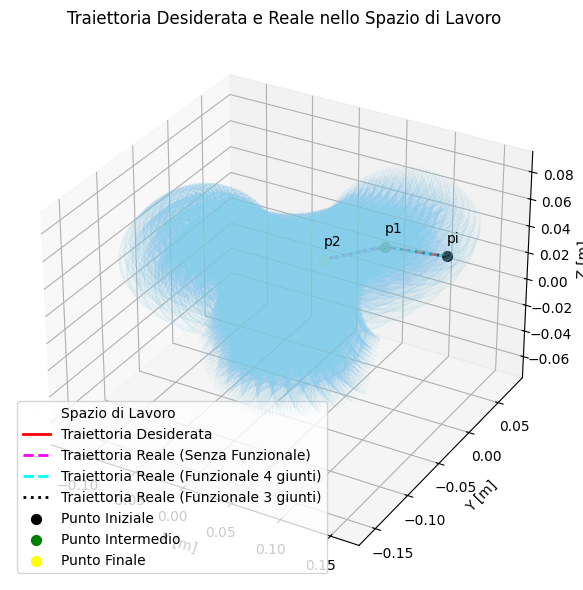

In [4]:
points = np.loadtxt("punti_spazio_lavoro.txt", skiprows=1)
#Plot della traiettoria desiderata e reale nello spazio di lavoro (per verificare graficamente se si trova al suo interno)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')


#Plot dello spazio di lavoro
ax.scatter(points[:, 0], points[:, 1], points[:, 2], s=0.01, c='skyblue', alpha=0.3, label='Spazio di Lavoro')

#Plot della traiettoria desiderata
ax.plot(Pd[:, 0], Pd[:, 1], Pd[:, 2], c='red', linewidth=2, label='Traiettoria Desiderata')
#Plot della traiettoria reale con e senza ridondanza
ax.plot(p_ee[:, 0], p_ee[:, 1], p_ee[:, 2], c='magenta', linewidth=2, linestyle='--', label='Traiettoria Reale (Senza Funzionale)')
ax.plot(p_ee_func[:, 0], p_ee_func[:, 1], p_ee_func[:, 2], c='cyan', linewidth=2, linestyle='--', label='Traiettoria Reale (Funzionale 4 giunti)')
ax.plot(p_ee_func3[:, 0], p_ee_func3[:, 1], p_ee_func3[:, 2], c='black', linewidth=2, linestyle=':', label='Traiettoria Reale (Funzionale 3 giunti)')


ax.scatter(P0[0], P0[1], P0[2], c='black', s=50, label="Punto Iniziale")
ax.text(P0[0], P0[1], P0[2] + 0.01, "pi", color='black', zorder=10)
ax.scatter(P1[0], P1[1], P1[2], c='green', s=50, label="Punto Intermedio")
ax.text(P1[0], P1[1], P1[2] + 0.01, "p1", color='black', zorder=10)
ax.scatter(P2[0], P2[1], P2[2], c='yellow', s=50, label="Punto Finale")
ax.text(P2[0], P2[1], P2[2] + 0.01, "p2", color='black', zorder=10)


ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_zlabel('Z [m]')
ax.set_title('Traiettoria Desiderata e Reale nello Spazio di Lavoro')
ax.legend()
plt.tight_layout()
plt.show()


## 1.5 Animazione 3D della simulazione: confronto con e senza funzionale
Le tre celle generano un'animazione 3D interattiva del robot in movimento,
una per ciascun caso simulato. Seguono la stessa struttura: ad
ogni frame viene ridisegnata la **catena cinematica** nella configurazione
articolare corrente, insieme alla traiettoria desiderata e alla scia
percorsa dall'end-effector fino all'istante corrente.

La catena è rappresentata come sequenza di segmenti colorati che collegano
i giunti, con un colore diverso per ogni link per facilitare la lettura
visiva del comportamento articolare:

In [9]:
# Animazione senza funzionale

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
plt.suptitle("Simulazione 3D - senza funzionale", fontsize=16)

def update(counter):
    ax.clear()

    ax.plot([0, p_1[counter, 0]], [0, p_1[counter, 1]], [0, p_1[counter, 2]], lw=4, color='red')
    ax.plot(p_1[counter, 0], p_1[counter, 1], p_1[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_1[counter, 0], p_2[counter, 0]], [p_1[counter, 1], p_2[counter, 1]], [p_1[counter, 2], p_2[counter, 2]], lw=4, color='yellow')
    ax.plot(p_2[counter, 0], p_2[counter, 1], p_2[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_2[counter, 0], p_L[counter, 0]], [p_2[counter, 1], p_L[counter, 1]], [p_2[counter, 2], p_L[counter, 2]], lw=4, color='green')
    ax.plot(p_L[counter, 0], p_L[counter, 1], p_L[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_L[counter, 0], p_3[counter, 0]], [p_L[counter, 1], p_3[counter, 1]], [p_L[counter, 2], p_3[counter, 2]], lw=4, color='orange')
    ax.plot(p_3[counter, 0], p_3[counter, 1], p_3[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_3[counter, 0], p_ee[counter, 0]], [p_3[counter, 1], p_ee[counter, 1]], [p_3[counter, 2], p_ee[counter, 2]], lw=4, color='purple')
    ax.plot(p_ee[counter, 0], p_ee[counter, 1], p_ee[counter, 2], marker='.', markersize=15, color='#3CB371')

    ax.plot(Pd[:, 0], Pd[:, 1], Pd[:, 2], color='red', label='Traiettoria desiderata')
    ax.plot(p_ee[:counter+1, 0], p_ee[:counter+1, 1], p_ee[:counter+1, 2], lw=2, color='blue', label='Tracciata')
    
    ax.set_xlabel('X [m]', fontsize=12)
    ax.set_ylabel('Y [m]', fontsize=12)
    ax.set_zlabel('Z [m]', fontsize=12)
    ax.set_title(f"Tempo: {counter * dt:.2f} s")
    ax.legend(loc='upper right')
    ax.xaxis.set_major_locator(MultipleLocator(0.01))
    ax.yaxis.set_major_locator(MultipleLocator(0.01))
    ax.set_box_aspect([7, 3, 3])

ani = FuncAnimation(fig, update, frames=range(0,len(time),40), interval=50, repeat=False)
plt.close(fig)
from IPython.display import HTML
HTML(ani.to_jshtml())

In [10]:
# Animazione con funzionale

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
plt.suptitle("Simulazione 3D - con funzionale (4 giunti)", fontsize=16)

def update(counter):
    ax.clear()

    ax.plot([0, p_1_func[counter, 0]], [0, p_1_func[counter, 1]], [0, p_1_func[counter, 2]], lw=4, color='red')
    ax.plot(p_1_func[counter, 0], p_1_func[counter, 1], p_1_func[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_1_func[counter, 0], p_2_func[counter, 0]], [p_1_func[counter, 1], p_2_func[counter, 1]], [p_1_func[counter, 2], p_2_func[counter, 2]], lw=4, color='yellow')
    ax.plot(p_2_func[counter, 0], p_2_func[counter, 1], p_2_func[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_2_func[counter, 0], p_L_func[counter, 0]], [p_2_func[counter, 1], p_L_func[counter, 1]], [p_2_func[counter, 2], p_L_func[counter, 2]], lw=4, color='green')
    ax.plot(p_L_func[counter, 0], p_L_func[counter, 1], p_L_func[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_L_func[counter, 0], p_3_func[counter, 0]], [p_L_func[counter, 1], p_3_func[counter, 1]], [p_L_func[counter, 2], p_3_func[counter, 2]], lw=4, color='orange')
    ax.plot(p_3_func[counter, 0], p_3_func[counter, 1], p_3_func[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_3_func[counter, 0], p_ee_func[counter, 0]], [p_3_func[counter, 1], p_ee_func[counter, 1]], [p_3_func[counter, 2], p_ee_func[counter, 2]], lw=4, color='purple')
    ax.plot(p_ee_func[counter, 0], p_ee_func[counter, 1], p_ee_func[counter, 2], marker='.', markersize=15, color='#3CB371')

    ax.plot(Pd[:, 0], Pd[:, 1], Pd[:, 2], color='red', label='Traiettoria desiderata')
    ax.plot(p_ee_func[:counter+1, 0], p_ee_func[:counter+1, 1], p_ee_func[:counter+1, 2], lw=2, color='blue', label='Tracciata')

    ax.set_xlabel('X [m]', fontsize=12)
    ax.set_ylabel('Y [m]', fontsize=12)
    ax.set_zlabel('Z [m]', fontsize=12)
    ax.set_title(f"Tempo: {counter * dt:.2f} s")
    ax.legend(loc='upper right')
    ax.xaxis.set_major_locator(MultipleLocator(0.01))
    ax.yaxis.set_major_locator(MultipleLocator(0.01))
    ax.set_box_aspect([7, 3, 3])

ani = FuncAnimation(fig, update, frames=range(0,len(time),40), interval=50, repeat=False)
plt.close(fig)
from IPython.display import HTML
HTML(ani.to_jshtml())

In [11]:
# Animazione con funzionale (3 giunti)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
plt.suptitle("Simulazione 3D - con funzionale (3 giunti)", fontsize=16)

def update(counter):
    ax.clear()

    ax.plot([0, p_1_func3[counter, 0]], [0, p_1_func3[counter, 1]], [0, p_1_func3[counter, 2]], lw=4, color='red')
    ax.plot(p_1_func3[counter, 0], p_1_func3[counter, 1], p_1_func3[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_1_func3[counter, 0], p_2_func3[counter, 0]], [p_1_func3[counter, 1], p_2_func3[counter, 1]], [p_1_func3[counter, 2], p_2_func3[counter, 2]], lw=4, color='yellow')
    ax.plot(p_2_func3[counter, 0], p_2_func3[counter, 1], p_2_func3[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_2_func3[counter, 0], p_L_func3[counter, 0]], [p_2_func3[counter, 1], p_L_func3[counter, 1]], [p_2_func3[counter, 2], p_L_func3[counter, 2]], lw=4, color='green')
    ax.plot(p_L_func3[counter, 0], p_L_func3[counter, 1], p_L_func3[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_L_func3[counter, 0], p_3_func3[counter, 0]], [p_L_func3[counter, 1], p_3_func3[counter, 1]], [p_L_func3[counter, 2], p_3_func3[counter, 2]], lw=4, color='orange')
    ax.plot(p_3_func3[counter, 0], p_3_func3[counter, 1], p_3_func3[counter, 2], marker='.', markersize=12, color='black')

    ax.plot([p_3_func3[counter, 0], p_ee_func3[counter, 0]], [p_3_func3[counter, 1], p_ee_func3[counter, 1]], [p_3_func3[counter, 2], p_ee_func3[counter, 2]], lw=4, color='purple')
    ax.plot(p_ee_func3[counter, 0], p_ee_func3[counter, 1], p_ee_func3[counter, 2], marker='.', markersize=15, color='#3CB371')

    ax.plot(Pd[:, 0], Pd[:, 1], Pd[:, 2], color='red', label='Traiettoria desiderata')
    ax.plot(p_ee_func3[:counter+1, 0], p_ee_func3[:counter+1, 1], p_ee_func3[:counter+1, 2], lw=2, color='blue', label='Tracciata')

    ax.set_xlabel('X [m]', fontsize=12)
    ax.set_ylabel('Y [m]', fontsize=12)
    ax.set_zlabel('Z [m]', fontsize=12)
    ax.set_title(f"Tempo: {counter * dt:.2f} s")
    ax.legend(loc='upper right')
    ax.xaxis.set_major_locator(MultipleLocator(0.01))
    ax.yaxis.set_major_locator(MultipleLocator(0.01))
    ax.set_box_aspect([7, 3, 3])

ani = FuncAnimation(fig, update, frames=range(0,len(time),40), interval=50, repeat=False)
plt.close(fig)
from IPython.display import HTML
HTML(ani.to_jshtml())

## 1.6 Analisi delle escursioni articolari: confronto con e senza funzionali

Questa cella visualizza l'evoluzione temporale degli angoli di giunto
nei tre casi simulati, sovrapponendoli in un grafico per ciascun giunto.
Ogni subplot mostra tre riferimenti orizzontali che permettono di valutare
immediatamente il comportamento articolare:

- **centro corsa**: il punto equidistante dai due limiti, verso cui il
  funzionale spinge i giunti
- **limite superiore** e **limite inferiore**: i vincoli fisici del giunto,
  il cui superamento causerebbe collisioni meccaniche

Il confronto tra la curva continua (senza funzionale) e quelle tratteggiate
(con funzionale) permette di verificare visivamente l'effetto
dell'ottimizzazione nel nullo: i giunti con funzionale dovrebbero mantenersi
più vicini al centro corsa, con margini di sicurezza maggiori dai limiti.

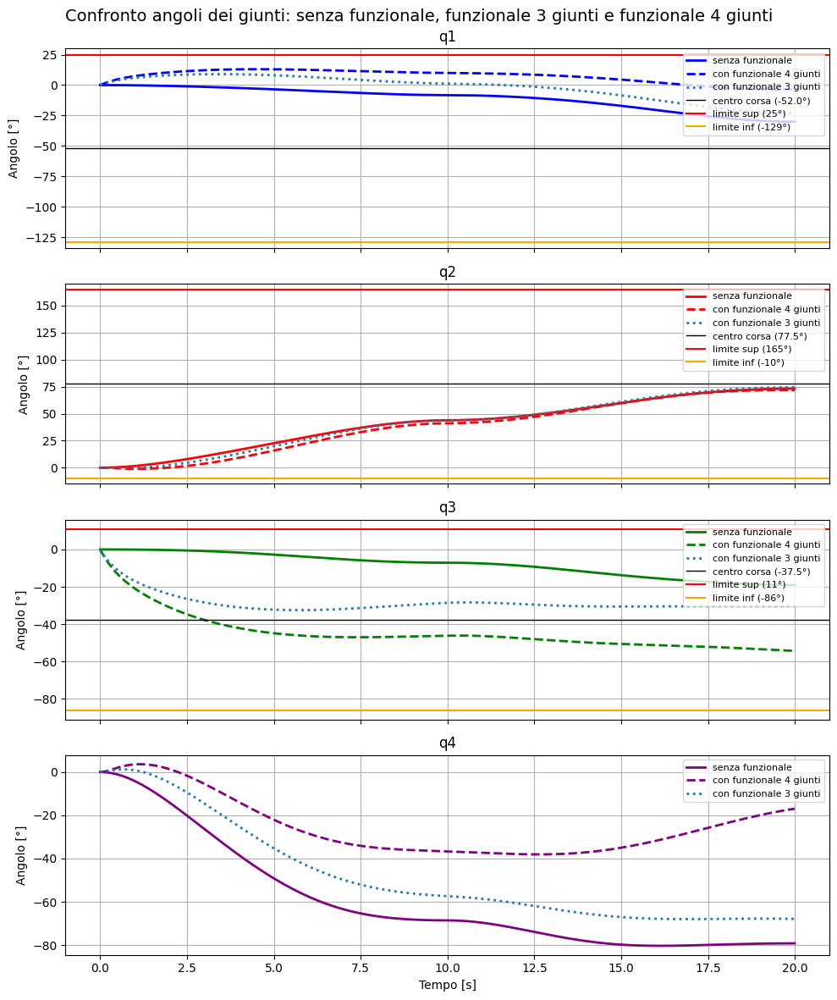

In [12]:
fig, axes = plt.subplots(4, 1, figsize=(10, 12), sharex=True)
labels  = ['q1', 'q2', 'q3', 'q4']
colors  = ['blue', 'red', 'green', 'purple']

qm = [-129, -10, -86, -360]
qM = [25,   165,  11,  0]
centri = [(-129 + 25) / 2, (-10 + 165) / 2, (-86 + 11) / 2, (0 + 360) / 2]

for i in range(4):
    q = np.degrees(Qd[:, i])
    q_func   = np.degrees(Qd_func[:, i])
    q_func3 = np.degrees(Qd_func3[:, i])
    axes[i].plot(time, q, color=colors[i], linewidth=2, label='senza funzionale')
    axes[i].plot(time, q_func,   color=colors[i], linestyle='--', linewidth=2, label='con funzionale 4 giunti')
    axes[i].plot(time, q_func3, linestyle=':', linewidth=2, label='con funzionale 3 giunti')
    if i < 3:
        axes[i].axhline(centri[i], color='black', linewidth=1, label=f'centro corsa ({centri[i]:.1f}°)')
        axes[i].axhline(qM[i], color='red', linewidth=1.5, label=f'limite sup ({qM[i]}°)')
        axes[i].axhline(qm[i], color='orange', linewidth=1.5, label=f'limite inf ({qm[i]}°)')
        axes[i].set_ylim(qm[i] - 5, qM[i] + 5)
    else:
        axes[i].set_title('q4 - giunto continuo')
    
    axes[i].set_ylabel('Angolo [°]')
    axes[i].set_title(f'{labels[i]}')
    axes[i].legend(loc='upper right', fontsize=8)
    axes[i].grid(True)

axes[3].set_xlabel('Tempo [s]')
plt.suptitle('Confronto angoli dei giunti: senza funzionale, funzionale 3 giunti e funzionale 4 giunti', fontsize=14)
plt.tight_layout()
plt.show()

E' stata definita una misura di distanza media normalizzata dai fine corsa. Per ciascun giunto viene calcolata la distanza dal limite articolare più vicino e normalizzata rispetto all’intervallo di movimento disponibile. La grandezza risultante viene successivamente mediata sui tre giunti soggetti a limitazione articolare

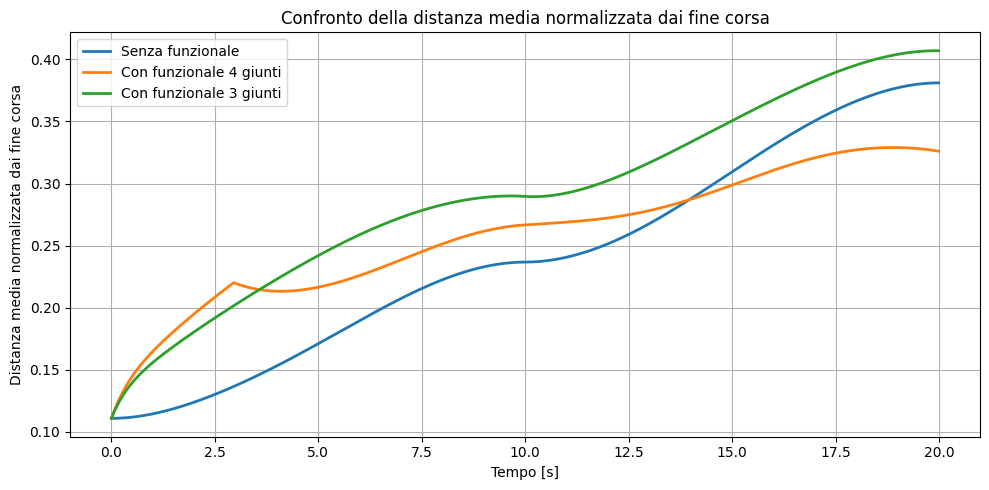

In [13]:
# Distanza media normalizzata dai fine corsa nei tre casi
q_min_deg = np.array([-129, -10, -86])
q_max_deg = np.array([25, 165, 11])
range_deg = q_max_deg - q_min_deg

def distanza_media_normalizzata(Q_traj):
    # Converto in gradi solo i primi tre giunti, perché il funzionale è valutato su questi
    q_deg = np.degrees(Q_traj[:, :3])

    # Distanza normalizzata dal limite inferiore e superiore
    distanza_inf = (q_deg - q_min_deg) / range_deg
    distanza_sup = (q_max_deg - q_deg) / range_deg

    # Per ogni istante e per ogni giunto considero la distanza dal fine corsa più vicino
    distanza_da_limite = np.minimum(distanza_inf, distanza_sup)

    # Media sui tre giunti a ogni istante di tempo
    distanza_media = np.mean(distanza_da_limite, axis=1)

    return distanza_media

dist_senza_func = distanza_media_normalizzata(Qd)
dist_func_4g = distanza_media_normalizzata(Qd_func)
dist_func_3g = distanza_media_normalizzata(Qd_func3)

plt.figure(figsize=(10, 5))
plt.plot(time, dist_senza_func, linewidth=2, label='Senza funzionale')
plt.plot(time, dist_func_4g, linewidth=2, label='Con funzionale 4 giunti')
plt.plot(time, dist_func_3g, linewidth=2, label='Con funzionale 3 giunti')
plt.xlabel('Tempo [s]')
plt.ylabel('Distanza media normalizzata dai fine corsa')
plt.title('Confronto della distanza media normalizzata dai fine corsa')
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig('distanza_media_finecorsa.png')
plt.show()



## 1.7 Criterio di selezione del caso migliore

Poiché i due funzionali producono errori di tracking confrontabili, la scelta 
è stata effettuata privilegiando la sicurezza articolare tramite uno score pesato:

$$
\text{score} = 0.30 \cdot d_{\min} + 0.35 \cdot d_{\text{media}} - 0.35 \cdot \frac{t_{\text{vicino}}}{100}
$$

dove $d_{\min}$ e $d_{\text{media}}$ sono da massimizzare (più lontano dai limiti 
è meglio) e $t_{\text{vicino}}$ è da minimizzare (meno tempo vicino ai limiti è meglio).
Per confrontare in modo omogeneo i due funzionali, le metriche empiriche sono state calcolate sugli stessi giunti, cioè q_1, q_2, q_3, che sono quelli caratterizzati da limiti articolari fisicamente più rilevanti. Il quarto giunto è stato escluso dalla valutazione perché presenta un intervallo di rotazione più ampio e non rappresenta il principale vincolo di fine corsa nel confronto.

In [15]:
q_min_deg = np.array([-129, -10, -86])
q_max_deg = np.array([25, 165, 11])
range_deg = q_max_deg - q_min_deg


def metriche_empiriche(Q_traj, error_traj, nome_caso):
    q_deg = np.degrees(Q_traj[:, :3])

    # Distanza normalizzata dal limite inferiore e superiore
    distanza_inf = (q_deg - q_min_deg) / range_deg
    distanza_sup = (q_max_deg - q_deg) / range_deg

    # Per ogni istante e per ogni giunto considero la distanza dal fine corsa più vicino
    distanza_da_limite = np.minimum(distanza_inf, distanza_sup)

    # Metriche sui fine corsa, solo q1-q2-q3
    distanza_media = np.mean(distanza_da_limite)
    distanza_minima = np.min(distanza_da_limite)

    # Percentuale di campioni in cui almeno un giunto è vicino al fine corsa
    # Soglia 0.10 = entro il 10% del range articolare
    vicino_finecorsa = np.any(distanza_da_limite < 0.10, axis=1)
    percentuale_vicino_finecorsa = 100 * np.mean(vicino_finecorsa)


    return {
        'caso': nome_caso,
        'distanza_media': distanza_media,
        'distanza_minima': distanza_minima,
        'percentuale_vicino_finecorsa': percentuale_vicino_finecorsa,
    }


m4 = metriche_empiriche(Qd_func, error_func.flatten(), 'Funzionale 4 giunti')
m3 = metriche_empiriche(Qd_func3, error_func3.flatten(), 'Funzionale 3 giunti')

print('\n VALUTAZIONE DEI FUNZIONALI')
for m in [m4, m3]:
    print(f"\n{m['caso']}")
    print(f"  Distanza media dai fine corsa q1-q3:  {m['distanza_media']:.4f}")
    print(f"  Distanza minima dai fine corsa q1-q3: {m['distanza_minima']:.4f}")
    print(f"  Tempo vicino ai fine corsa [%]:       {m['percentuale_vicino_finecorsa']:.2f}")

# Criterio di scelta del caso migliore

def score_finecorsa(m):
    # Metriche da massimizzare
    distanza_minima = m['distanza_minima']
    distanza_media = m['distanza_media']

    # Metrica da minimizzare, quindi metto il segno meno
    tempo_vicino = -m['percentuale_vicino_finecorsa']

    return (0.30 * distanza_minima + 0.35 * distanza_media + 0.35 * tempo_vicino / 100)


for m in [m4, m3]:
    m['score_finecorsa'] = score_finecorsa(m)

best_metriche = max([m4, m3], key=lambda m: m['score_finecorsa'])

print('\nPUNTEGGIO FINE CORSA')
for m in [m4, m3]:
    print(f"{m['caso']}: {m['score_finecorsa']:.4f}")

print('\nConclusione:')
print(f"  Il caso migliore rispetto ai fine corsa risulta: {best_metriche['caso']}")




 VALUTAZIONE DEI FUNZIONALI

Funzionale 4 giunti
  Distanza media dai fine corsa q1-q3:  0.2585
  Distanza minima dai fine corsa q1-q3: 0.0508
  Tempo vicino ai fine corsa [%]:       55.30

Funzionale 3 giunti
  Distanza media dai fine corsa q1-q3:  0.2903
  Distanza minima dai fine corsa q1-q3: 0.0551
  Tempo vicino ai fine corsa [%]:       15.45

PUNTEGGIO FINE CORSA
Funzionale 4 giunti: -0.0878
Funzionale 3 giunti: 0.0641

Conclusione:
  Il caso migliore rispetto ai fine corsa risulta: Funzionale 3 giunti


## 1.8 CONCLUSIONI

I risultati suggeriscono quindi che l’inclusione del quarto giunto all’interno del funzionale introduce un vincolo aggiuntivo che non apporta benefici reali, poiché tale giunto non è soggetto a limiti articolari significativi. Al contrario, concentrando l’ottimizzazione esclusivamente sui giunti effettivamente limitati, il sistema riesce a distribuire in modo più efficace il contributo del compito secondario, mantenendo il manipolatore più lontano dai fine corsa senza compromettere la precisione del tracking.